# hiNiche on single-cell spatial data (single slice): human breast cancer Xenium

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`).

This notebook applies hiNiche (`hiNiche_img`, cell → niche) to a single Xenium slice of human breast cancer. The cell / niche embeddings are written to the AnnData and clustered with GPU-accelerated Leiden (`rapids_singlecell`). This dataset has **no ground-truth labels**, so the clusters are only visualized (no NMI / ARI evaluation).

## 1. Imports

In [1]:
import config
import utils
import model
from train import run_train_img

import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import os
import glob
import warnings
import json
from tqdm import tqdm

# GPU-accelerated single-cell tools (Leiden clustering).
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
import sys
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))
import rapids_singlecell as rsc

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

/hpc/home/wz220/miniconda3/envs/hiNiche/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration

Data paths, the patch directory (`PATCH_LOC`) and model / training hyperparameters. There is no ground-truth column, so the clustering granularity is set by the Leiden resolution (`leiden_resolution`).

In [2]:
SAMPLE = "Breast_cancer_Xenium_single_slice"

# Data paths: a single-slice AnnData (raw counts in adata.X)
h5_path = f"DATA/{SAMPLE}/Xenium_Breast_Cancer.h5ad"

# Patch save path
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache"

# Model save path (if the file exists, the model is loaded and training is skipped)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Model / training hyperparameters
single_patch = True    # the whole slice is used as a single patch
n_pcs       = 30
graph_knn   = 12
niche_knn   = 20
hidden_dim  = 32
lr          = 0.005
num_epochs  = 100
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
seed        = 42
leiden_knn  = 15       # neighbors of the KNN graph used for Leiden
leiden_resolution = 0.2   # no ground truth: higher -> more clusters
device      = "cuda:0"

## 3. Load data

Read the AnnData and show per-cell QC metrics (cell and nucleus area) in space.

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'ensemble_id', 'type'
    obsm: 'spatial'


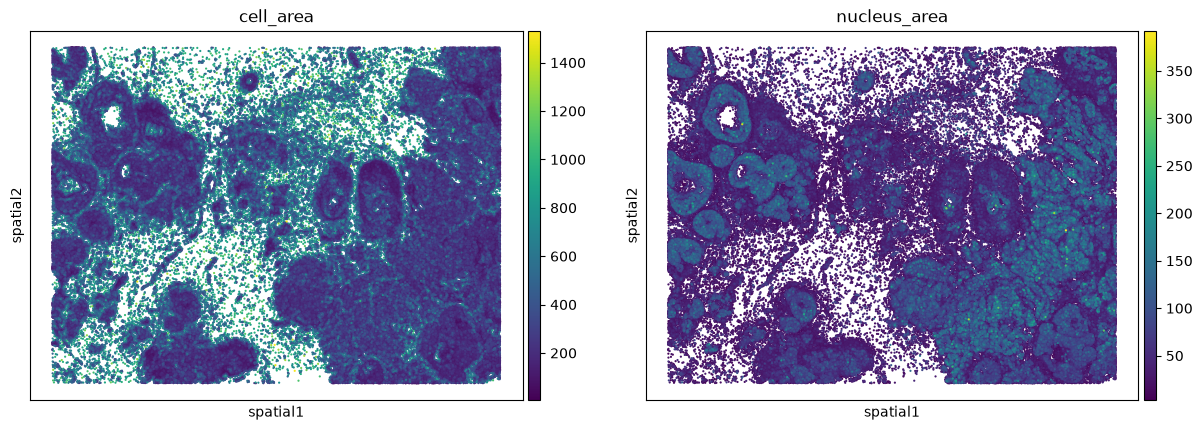

In [3]:
adata = sc.read(h5_path)
adata.var_names_make_unique()
print(adata)

sc.pl.embedding(adata, basis="spatial", color=["cell_area", "nucleus_area"], s=10)

## 4. Build graphs, niches and mini-batch

Normalize + log1p the raw counts, scale + PCA, build KNN niches (`niche_knn` cells per niche), the cell graph (expression PCA KNN) and the niche graph (spatial KNN), then cache the slice as a single block in `PATCH_LOC`.

In [4]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

X_backup = adata.X.copy()
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=n_pcs)
adata.X = X_backup

adata.obsm["X_input"] = adata.X
adata.obsm["X_mle"] = adata.layers["counts"]
spatial_coords_px = adata.obsm["spatial"]

# Each niche = a center cell and its niche_knn nearest cells (including itself)
S_c2n_all, _, _ = utils.build_cell_niche_mapping_knn(spatial_coords_px, k_niche = niche_knn)

cell_edges = utils.build_spot_knn_graph(adata.obsm["X_pca"], graph_knn)    # cell graph: expression (PCA) KNN
niche_edges = utils.build_spot_knn_graph(spatial_coords_px, graph_knn)     # niche graph: spatial KNN
batch_mask, block_ids = utils.make_cell_block_masks(spatial_coords_px, S_c2n = S_c2n_all, single_patch = single_patch)

# Remove old blocks, otherwise the loader would also read leftovers from a previous run
for f in glob.glob(os.path.join(PATCH_LOC, "block_*.pt")):
    os.remove(f)
utils.build_cell_subgraph_data(adata, ref_matrix = None,
                               cell_edges = cell_edges,
                               niche_edges = niche_edges,
                               S_c2n_all = S_c2n_all,
                               batch_mask = batch_mask,
                               block_ids = block_ids,
                               save_dir = PATCH_LOC)

sample_number = {"cell": S_c2n_all.shape[0], "niche": S_c2n_all.shape[1]}

[Log] Active niches: 167780, Cells per niche (k): 20
[Log] 3352948 edges generated from 167780 nodes (k=12)
[Log] 2263048 edges generated from 167780 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:04<00:00,  4.07s/it]

[Log] saved 1 cell blocks → DATA/Breast_cancer_Xenium_single_slice/mini_batch_cache


## 5. Training

Single slice: pass a dict of unit numbers and a single patch directory. If `MODEL_SAVE_DIR` already exists, the model is loaded and training is skipped. Embeddings are written to `adata.obsm["X_cell_emb"]` and `adata.obsm["X_niche_emb"]`.

In [5]:
emb_all, _ = run_train_img(sample_number,
                           PATCH_LOC = PATCH_LOC,
                           MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                           ref_matrix = None,
                           lr = lr,
                           in_dim = adata.n_vars,
                           hidden_dim = hidden_dim,
                           num_epochs = num_epochs,
                           edge_drop = edge_drop,
                           member_drop = member_drop,
                           neg_samples = neg_samples,
                           tau = tau,
                           seed = seed,
                           device = device)

# With KNN niches every cell is a niche center, so niche embeddings are aligned with cells as well
adata.obsm["X_cell_emb"]  = emb_all["cell"].detach().cpu().numpy()
adata.obsm["X_niche_emb"] = emb_all["niche"].detach().cpu().numpy()

Epoch 100: 100%|██████████| 1/1 [00:00<00:00,  2.57it/s, cl=2.7458]


Training finished!
Model saved to DATA/Breast_cancer_Xenium_single_slice/checkpoint.pt


generating embeddings (slice 0)...: 100%|██████████| 1/1 [00:00<00:00,  2.44it/s]


## 6. Clustering and visualization

GPU-accelerated Leiden clustering (`rapids_singlecell`) on the cell and niche embeddings, shown in space. Labels are stored in `adata.obs["leiden_cell"]` / `adata.obs["leiden_niche"]`.

cell: 12 Leiden clusters
niche: 10 Leiden clusters


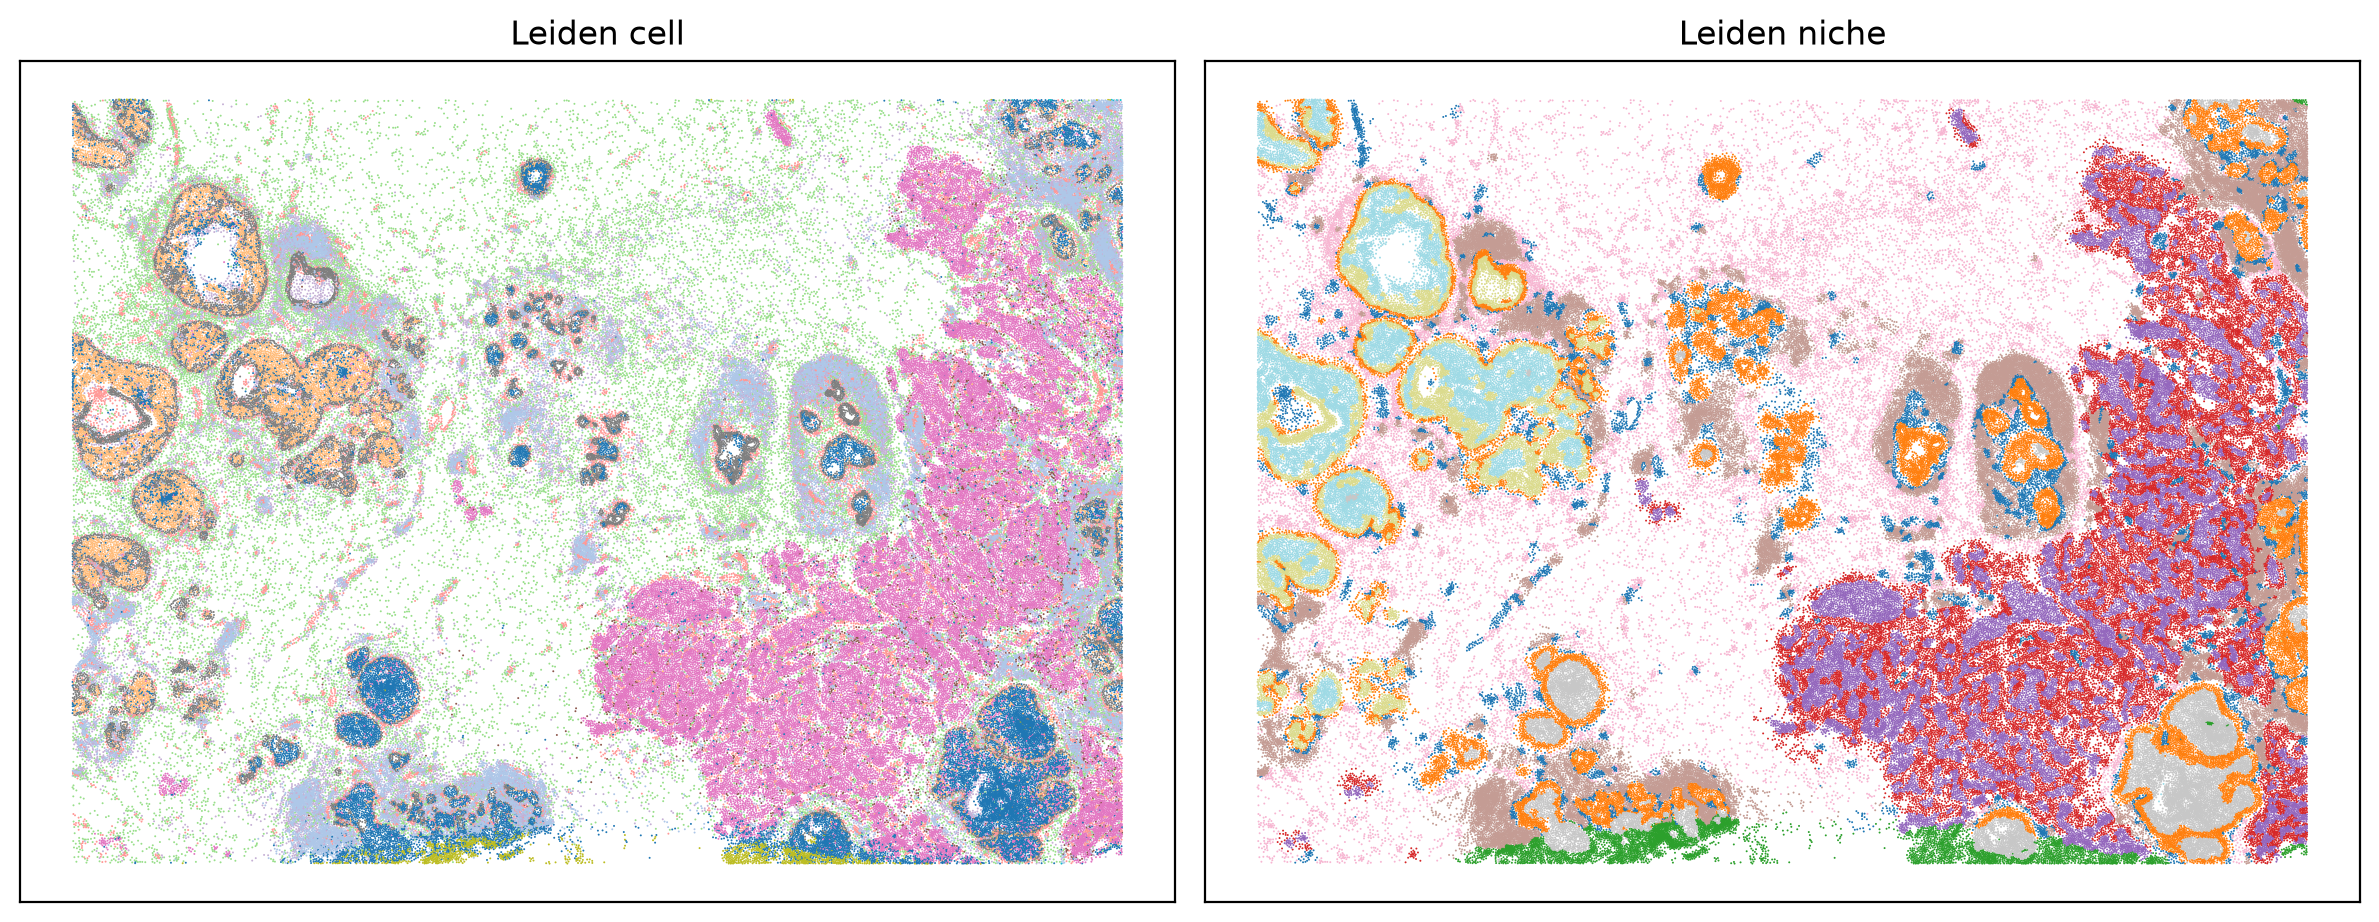

In [6]:
spatial = adata.obsm["spatial"]
x, y = spatial[:, 0], spatial[:, 1]

# Leiden on the GPU: KNN graph on each embedding, then Leiden
for level in ["cell", "niche"]:
    adata_tmp = ad.AnnData(np.asarray(adata.obsm[f"X_{level}_emb"]))
    rsc.pp.neighbors(adata_tmp, use_rep="X", n_neighbors=leiden_knn)
    rsc.tl.leiden(adata_tmp, resolution=leiden_resolution, random_state=seed)
    adata.obs[f"leiden_{level}"] = pd.Categorical(adata_tmp.obs["leiden"].values)
    print(f"{level}: {adata.obs[f'leiden_{level}'].nunique()} Leiden clusters")

point_size = 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=200)
panels = [(adata.obs["leiden_cell"].cat.codes,  "Leiden cell"),
          (adata.obs["leiden_niche"].cat.codes, "Leiden niche")]
for ax, (c, title) in zip(axes, panels):
    ax.scatter(x, y, c=c, s=point_size, linewidths=0, cmap="tab20")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal")
    ax.set_title(title)
plt.tight_layout()
plt.show()